# K-Nearest Neighbors (KNN)
**Unit 4 · Lesson 5 | PV Time Series**  
Instructor: Sepehr Shakibi  
[Applied Machine Learning and Deep Learning for Photovoltaics with Python](https://github.com/SepehrShakibi/applied-ml-dl-for-photovoltaics-with-python)

Following the KNN slides, predict next-hour production classes with `KNeighborsClassifier` and next-hour power with `KNeighborsRegressor`. Use the existing chronological partitions and measurements at time t.

**Goals:** understand neighbor voting and averaging; explain distance and scaling; compare K explicitly; explore distance weighting and Manhattan distance; inspect actual neighbors; freeze choices using validation before final test.

This lesson focuses on KNN, with no baselines, repeated EDA or new cleaning. Comparing KNN settings alone does not establish superiority over simple forecasting rules.

## 1. Setup
Run from the project root. Download the prepared raw split CSVs, not scaled exports. If the downloaded folder layout differs, update `CONFIG["data_dir"]` below.

**Colab:** runtime storage is temporary. Download saved outputs or copy them to mounted Drive before the runtime ends. `gdown` does not mount Drive.

In [3]:
%pip install -q gdown
# %pip install -q numpy pandas matplotlib scikit-learn joblib

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
)

In [5]:
!gdown --folder https://drive.google.com/drive/folders/1lFetK1YgncT5GPdLQFNrkuy8UWf-6881

Retrieving folder contents
Retrieving folder 14T5F5gwA0GGtPapainnN03f1IMhkXgec processed
Retrieving folder 1v372EjkxWn-8UdlhIvcPOS0ohwMXefZE pv_images
Processing file 1RFZRlUEIun3Z36gYpLClX8PRI4Og0Lql pv_images_test.csv
Processing file 1ZAqeFxVdPZu_uqfHT3Q7QRytm1CvbOnU pv_images_train.csv
Processing file 1pW98UOlS7Mh4LKHooN_1pzJjetJCnQFg pv_images_unknown.csv
Processing file 1hkMI_UN5FwmoSOfSXNuhz2zngOEjO-7k pv_images_validation.csv
Retrieving folder 1z994qLWlxE0mszwY1rLm8_1wQaso5gDB pv_time_series
Processing file 1DKNF0q9QHGBQSywBeNCC37bCEexxyWFq column_mapping.csv
Processing file 1bJlRxrYgcVEA1u383vq-F5g7E_lUQW3A pv_time_series_preprocessing.joblib
Processing file 1H5WyuYLz-Hye9SERAy1O3pu4grXmtLcJ pv_time_series_test_encoded.csv
Processing file 1ErXBDQHcCYa3aFv8rL0u7GTJkutuY5On pv_time_series_test_standardized.csv
Processing file 1IB0qv5K87J6MGmc8Q7SG-Q0lC745In1r pv_time_series_test.csv
Processing file 1nHbXSH4AxfpEwkwcqBfWOQVOI96SGaZQ pv_time_series_train_encoded.csv
Processing file

In [6]:
PROJECT_ROOT = os.path.abspath(".")
CONFIG = {
    "data_dir": os.path.join(PROJECT_ROOT, "data", "processed", "pv_time_series"),
    "output_dir": os.path.join(PROJECT_ROOT, "outputs", "04_05_k_nearest_neighbors"),
}

## 2. Load the prepared partitions
Retain the existing chronological 70/15/15 split. Do not randomly shuffle or rebuild the next-hour targets. Training labels were aligned within each partition, without crossing split boundaries.

The classification target already contains `low`, `medium`, `high`; low includes zero. Boundaries were learned from positive training targets in Unit 3. Use those labels unchanged; this lesson does not require `preparation_metadata.json`. These are teaching production categories, not fault labels. The regression target retains its original values and units (the physical unit is not verified).

In [7]:
train_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_train.csv"))
validation_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_validation.csv"))
test_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_test.csv"))

print("Train:", train_data.shape)
print("Validation:", validation_data.shape)
print("Test:", test_data.shape)
display(train_data.head())

Train: (4955, 25)
Validation: (1061, 25)
Test: (1061, 25)


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power,time_index,target_time_index,target_power_t_plus_1,target_class_t_plus_1
0,1,0.999852,1,1.0000,2,81,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,0,1,0.0,low
1,1,0.999852,2,0.9659,-1,86,0,900.2,10,0.0,...,0,0.0,0,0.0,0,0,1,2,0.0,low
2,1,0.999852,3,0.8660,0,87,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,2,3,0.0,low
3,1,0.999852,4,0.7071,-1,86,2,900.2,10,0.0,...,0,0.0,0,0.0,0,0,3,4,0.0,low
4,1,0.999852,5,0.5000,-1,86,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,4,5,0.0,low


## 3. Features and the two targets
Use the same measurements as the preceding lessons. Exclude both future targets and temporal alignment metadata from X. Current power is available at prediction time for rolling one-hour-ahead prediction; this is not day-ahead forecasting.

The classifier and regressor use the same inputs but different targets. Scaling applies only to X, so regression predictions need no inverse transform.

In [8]:
CLASS_NAMES = ["low", "medium", "high"]
TARGET = "target_class_t_plus_1"
NUMERIC_FEATURES = [
    "cosine_of_day", "cosine_of_hour", "air_temperature", "dewpoint",
    "wind_speed", "air_pressure", "solar_radiation",
    "pv_1_cosine_value_of_the_solar_incidence_angle", "pv_1_power",
    "pv_2_cosine_value_of_the_solar_incidence_angle", "pv_2_power",
    "pv_3_cosine_value_of_the_solar_incidence_angle", "pv_3_power",
    "pv_4_cosine_value_of_the_solar_incidence_angle", "pv_4_power",
    "pv_5_cosine_value_of_the_solar_incidence_angle", "pv_5_power",
]
CATEGORICAL_FEATURES = ["weather_condition"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_validation = validation_data[FEATURES]
y_validation = validation_data[TARGET]
X_test = test_data[FEATURES]
y_test = test_data[TARGET]

print("Number of inputs:", len(FEATURES))

Number of inputs: 18


In [9]:
y_train_power = train_data["target_power_t_plus_1"]
y_validation_power = validation_data["target_power_t_plus_1"]
y_test_power = test_data["target_power_t_plus_1"]
assert set(y_train.unique()) == set(CLASS_NAMES), "All three classes must occur in train."
assert len(X_train) >= 21, "The largest candidate K requires at least 21 training rows."
display(y_train.value_counts().reindex(CLASS_NAMES).rename("training support"))

,training support
target_class_t_plus_1,
low,3429
medium,765
high,761


## 4. The core idea: distance → neighbors → output
KNN is an instance-based (lazy) method. `fit` stores training examples and may build a search structure; it does not learn regression coefficients through epochs. Prediction finds K nearby **training** examples in feature space, not K adjacent hours.

- **Classification:** neighbors vote for a class.
- **Regression:** average the neighbors' target values.
- `weights="uniform"`: each neighbor has equal influence.
- `weights="distance"`: nearer neighbors have greater influence (inverse-distance weighting). Scikit-learn handles exact zero distances specially.

For vectors x and u:
\[
d_p(x,u)=\left(\sum_j|x_j-u_j|^p\right)^{1/p}.
\]
Minkowski with p=2 is Euclidean; p=1 is Manhattan. Distance depends on both preprocessing and the chosen metric.

**Small K:** more local, potentially sensitive to noise. **Large K:** smoother, potentially underfitting. Odd K does not eliminate ties in multiclass voting. Equal-distance neighbors can also make training-row order matter.

In [10]:
# Illustration only: these are not PV measurements.
neighbor_classes = pd.Series(["high", "high", "medium", "high", "low"])
neighbor_power = np.array([8.0, 6.0, 10.0, 4.0, 7.0])
print("Class votes:")
display(neighbor_classes.value_counts())
print("Uniform regression prediction:", neighbor_power.mean())
print("Weighted regression prediction:", np.average(neighbor_power, weights=[0.3, 0.2, 0.2, 0.2, 0.1]))

Class votes:


,count
high,3
medium,1
low,1


Uniform regression prediction: 7.0
Weighted regression prediction: 7.1000000000000005


## 5. Why scaling and category representation matter
Without scaling, large-valued measurements can dominate distance simply because of their units. `StandardScaler` uses training means and standard deviations and reuses them unchanged for validation/test. Scaling balances units, not physical importance; correlated PV channels can still give similar information repeated influence.

**Deliberate change from the Logistic Regression lesson:** weather is nominal, so use **one-hot encoding** rather than ordinal codes. Arbitrary ordered codes would impose arbitrary weather distances, particularly problematic for KNN. Standardize numeric inputs only and leave one-hot indicators at 0/1. With Euclidean distance, two different known weather categories contribute squared distance 2. Unknown weather becomes all zeros (`handle_unknown="ignore"`), which is a representation limitation, not a newly learned category.

Keep these steps inside a pipeline fitted only on train. Do not use previously scaled exports or fit a scaler on the full dataset. `OneHotEncoder(sparse_output=False)` requires scikit-learn >=1.2.

In [11]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("weather", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])

## 6. Classification: fit and validate each K
Compare K=3, 7 and 21 with Euclidean distance and uniform voting. Each pipeline gets its own cloned preprocessor. Evaluation is placed immediately after each fit: validation is used for comparison, never for fitting.

Accuracy is the overall correct fraction. Macro-F1 averages class F1 values equally. In `classification_report`, **support** is the number of true examples of each class, not the number predicted. `zero_division=0` assigns zero to undefined metrics. Train scores are resubstitution scores: queried training rows can find themselves as neighbors, so these are optimistic, especially for small K.

In [12]:
knn_k3 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsClassifier(n_neighbors=3, algorithm="kd_tree", weights="uniform", metric="minkowski", p=2)),
])
knn_k3.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['cosine_of_day',
                                                   'cosine_of_hour',
                                                   'air_temperature',
                                                   'dewpoint', 'wind_speed',
                                                   'air_pressure',
                                                   'solar_radiation',
                                                   'pv_1_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_1_power',
                                                   'pv_2_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_2_power',
                                                   'pv_3_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_3_power',
                                                   'pv_4_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_4_power',
                                                   'pv_5_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_5_power']),
                                                 ('weather',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['weather_condition'])])),
                ('knn',
                 KNeighborsClassifier(algorithm='kd_tree', n_neighbors=3))])

In [13]:
k3_validation_prediction = knn_k3.predict(X_validation)
k3_train_f1 = f1_score(y_train, knn_k3.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
k3_validation_f1 = f1_score(y_validation, k3_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
print("K=3 train macro-F1:", k3_train_f1)
print("K=3 validation macro-F1:", k3_validation_f1)
print("Validation accuracy:", accuracy_score(y_validation, k3_validation_prediction))
print(classification_report(y_validation, k3_validation_prediction, labels=CLASS_NAMES, zero_division=0))

K=3 train macro-F1: 0.9072056490799681
K=3 validation macro-F1: 0.8994264040193637
Validation accuracy: 0.941564561734213
              precision    recall  f1-score   support

         low       0.98      0.97      0.98       676
      medium       0.79      0.78      0.78       145
        high       0.92      0.95      0.94       240

    accuracy                           0.94      1061
   macro avg       0.90      0.90      0.90      1061
weighted avg       0.94      0.94      0.94      1061



In [14]:
knn_k7 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsClassifier(n_neighbors=7, algorithm="kd_tree", weights="uniform", metric="minkowski", p=2)),
])
knn_k7.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['cosine_of_day',
                                                   'cosine_of_hour',
                                                   'air_temperature',
                                                   'dewpoint', 'wind_speed',
                                                   'air_pressure',
                                                   'solar_radiation',
                                                   'pv_1_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_1_power',
                                                   'pv_2_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_2_power',
                                                   'pv_3_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_3_power',
                                                   'pv_4_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_4_power',
                                                   'pv_5_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_5_power']),
                                                 ('weather',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['weather_condition'])])),
                ('knn',
                 KNeighborsClassifier(algorithm='kd_tree', n_neighbors=7))])

In [15]:
k7_validation_prediction = knn_k7.predict(X_validation)
k7_train_f1 = f1_score(y_train, knn_k7.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
k7_validation_f1 = f1_score(y_validation, k7_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
print("K=7 train macro-F1:", k7_train_f1)
print("K=7 validation macro-F1:", k7_validation_f1)
print("Validation accuracy:", accuracy_score(y_validation, k7_validation_prediction))
print(classification_report(y_validation, k7_validation_prediction, labels=CLASS_NAMES, zero_division=0))

K=7 train macro-F1: 0.8822627282769616
K=7 validation macro-F1: 0.9017388207044473
Validation accuracy: 0.943449575871819
              precision    recall  f1-score   support

         low       0.99      0.97      0.98       676
      medium       0.79      0.80      0.79       145
        high       0.92      0.94      0.93       240

    accuracy                           0.94      1061
   macro avg       0.90      0.91      0.90      1061
weighted avg       0.94      0.94      0.94      1061



In [16]:
knn_k21 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsClassifier(n_neighbors=21, algorithm="kd_tree", weights="uniform", metric="minkowski", p=2)),
])
knn_k21.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['cosine_of_day',
                                                   'cosine_of_hour',
                                                   'air_temperature',
                                                   'dewpoint', 'wind_speed',
                                                   'air_pressure',
                                                   'solar_radiation',
                                                   'pv_1_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_1_power',
                                                   'pv_2_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_2_power',
                                                   'pv_3_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_3_power',
                                                   'pv_4_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_4_power',
                                                   'pv_5_cosine_value_of_the_solar_incidence_angle',
                                                   'pv_5_power']),
                                                 ('weather',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['weather_condition'])])),
                ('knn',
                 KNeighborsClassifier(algorithm='kd_tree', n_neighbors=21))])

In [17]:
k21_validation_prediction = knn_k21.predict(X_validation)
k21_train_f1 = f1_score(y_train, knn_k21.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
k21_validation_f1 = f1_score(y_validation, k21_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
print("K=21 train macro-F1:", k21_train_f1)
print("K=21 validation macro-F1:", k21_validation_f1)
print("Validation accuracy:", accuracy_score(y_validation, k21_validation_prediction))
print(classification_report(y_validation, k21_validation_prediction, labels=CLASS_NAMES, zero_division=0))

K=21 train macro-F1: 0.865751297063519
K=21 validation macro-F1: 0.8944916855631142
Validation accuracy: 0.939679547596607
              precision    recall  f1-score   support

         low       0.99      0.97      0.98       676
      medium       0.78      0.77      0.78       145
        high       0.91      0.95      0.93       240

    accuracy                           0.94      1061
   macro avg       0.89      0.90      0.89      1061
weighted avg       0.94      0.94      0.94      1061



,K,train_macro_f1,validation_macro_f1
0,3,0.907206,0.899426
1,7,0.882263,0.901739
2,21,0.865751,0.894492


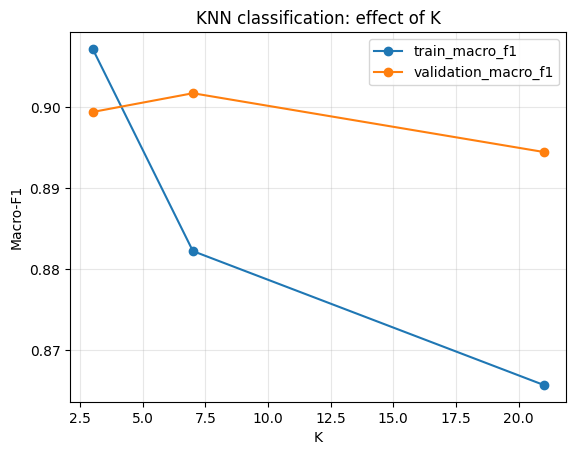

In [18]:
k_comparison = pd.DataFrame({
    "K": [3, 7, 21],
    "train_macro_f1": [k3_train_f1, k7_train_f1, k21_train_f1],
    "validation_macro_f1": [k3_validation_f1, k7_validation_f1, k21_validation_f1],
})
display(k_comparison)
k_comparison.plot(x="K", y=["train_macro_f1", "validation_macro_f1"], marker="o")
plt.ylabel("Macro-F1")
plt.title("KNN classification: effect of K")
plt.grid(alpha=0.3)
plt.show()

### Manual K choice
Review validation macro-F1 and per-class recall. Training scores alone cannot choose K. A large train–validation gap can indicate overfitting or temporal distribution change.

K=7 below is only a runnable teaching default, not a measured winner. Change the assignment and reason using validation before continuing. No automatic model selection is performed.

In [19]:
chosen_uniform_classifier = knn_k7
k_reason = "Teaching default K=7; replace with validation-based justification."
print(k_reason)

Teaching default K=7; replace with validation-based justification.


## 7. Change one setting at a time
At the selected K, compare the uniform Euclidean model against (1) distance-weighted Euclidean voting and (2) uniform Manhattan voting. These are controlled, separate comparisons, not an exhaustive search of every possible combination.

In [20]:
knn_weighted = clone(chosen_uniform_classifier)
knn_weighted.set_params(knn__weights="distance")
knn_weighted.fit(X_train, y_train)
weighted_validation_prediction = knn_weighted.predict(X_validation)
weighted_validation_f1 = f1_score(y_validation, weighted_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
print("weighted validation macro-F1:", weighted_validation_f1)
print(classification_report(y_validation, weighted_validation_prediction, labels=CLASS_NAMES, zero_division=0))

weighted validation macro-F1: 0.9037494456926831
              precision    recall  f1-score   support

         low       0.99      0.97      0.98       676
      medium       0.79      0.81      0.80       145
        high       0.92      0.94      0.93       240

    accuracy                           0.94      1061
   macro avg       0.90      0.91      0.90      1061
weighted avg       0.95      0.94      0.94      1061



In [ ]:
knn_manhattan = clone(chosen_uniform_classifier)
knn_manhattan.set_params(knn__p=1)
knn_manhattan.fit(X_train, y_train)
manhattan_validation_prediction = knn_manhattan.predict(X_validation)
manhattan_validation_f1 = f1_score(y_validation, manhattan_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
print("manhattan validation macro-F1:", manhattan_validation_f1)
print(classification_report(y_validation, manhattan_validation_prediction, labels=CLASS_NAMES, zero_division=0))

In [ ]:
uniform_validation_prediction = chosen_uniform_classifier.predict(X_validation)
uniform_validation_f1 = f1_score(y_validation, uniform_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
display(pd.DataFrame({
    "setting": ["Euclidean / uniform", "Euclidean / distance", "Manhattan / uniform"],
    "validation_macro_f1": [uniform_validation_f1, weighted_validation_f1, manhattan_validation_f1],
}))
# Manually choose one of the three fitted pipelines above.
chosen_classifier = chosen_uniform_classifier
classifier_reason = "Teaching default uniform Euclidean; replace with validation-based justification."
print(classifier_reason)

## 8. Inspect probabilities, errors and real neighbors
For uniform voting, each predicted probability is the fraction of selected neighbors in that class. With distance weights, it is the normalized weighted vote. These probabilities are not guaranteed to be calibrated; small K produces coarse uniform probabilities.

Columns follow `classes_`, not our display order. KNN has no linear coefficients or intrinsic coefficient-based feature importance. Instead, inspect the neighbors of a validation query, using exactly the fitted pipeline's transformed space.

In [ ]:
chosen_validation_prediction = chosen_classifier.predict(X_validation)
chosen_validation_probability = chosen_classifier.predict_proba(X_validation)
display(pd.DataFrame(chosen_validation_probability, columns=chosen_classifier.classes_, index=X_validation.index).head())
np.testing.assert_allclose(chosen_validation_probability.sum(axis=1), 1.0)
ConfusionMatrixDisplay.from_predictions(y_validation, chosen_validation_prediction, labels=CLASS_NAMES, cmap="Blues")
plt.title("KNN validation confusion matrix")
plt.show()

In [ ]:
query = X_validation.iloc[[0]]
query_transformed = chosen_classifier.named_steps["preprocessor"].transform(query)
neighbor_distances, neighbor_positions = chosen_classifier.named_steps["knn"].kneighbors(query_transformed)
neighbor_table = train_data.iloc[neighbor_positions[0]][["day", "hour", TARGET, "target_power_t_plus_1"]].copy()
neighbor_table.insert(0, "transformed_distance", neighbor_distances[0])
display(neighbor_table)
print("Actual validation class:", y_validation.iloc[0])
print("Predicted class:", chosen_classifier.predict(query)[0])
print("Neighbor vote counts (unweighted):")
display(neighbor_table[TARGET].value_counts())

## 9. KNN regression: average future power of neighbors
Now fit `KNeighborsRegressor` on the continuous next-hour target, using the same inputs and preprocessing. Classification-optimal K is not necessarily regression-optimal K, so evaluate K=3, 7 and 21 separately with uniform Euclidean averaging.

RMSE emphasizes large errors; MAE gives average absolute error. Both use original target units. R² can be negative. Only X is scaled. KNN regression cannot extrapolate beyond the range of selected neighbor targets; even distance-weighted predictions are local weighted averages.

In [ ]:
regressor_k3 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsRegressor(n_neighbors=3, weights="uniform", metric="minkowski", p=2)),
])
regressor_k3.fit(X_train, y_train_power)
regression_k3_prediction = regressor_k3.predict(X_validation)
regression_k3_train_rmse = np.sqrt(mean_squared_error(y_train_power, regressor_k3.predict(X_train)))
regression_k3_validation_rmse = np.sqrt(mean_squared_error(y_validation_power, regression_k3_prediction))
print("K=3 train RMSE:", regression_k3_train_rmse)
print("K=3 validation RMSE:", regression_k3_validation_rmse)
print("Validation MAE:", mean_absolute_error(y_validation_power, regression_k3_prediction))
print("Validation R2:", r2_score(y_validation_power, regression_k3_prediction))

In [ ]:
regressor_k7 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsRegressor(n_neighbors=7, weights="uniform", metric="minkowski", p=2)),
])
regressor_k7.fit(X_train, y_train_power)
regression_k7_prediction = regressor_k7.predict(X_validation)
regression_k7_train_rmse = np.sqrt(mean_squared_error(y_train_power, regressor_k7.predict(X_train)))
regression_k7_validation_rmse = np.sqrt(mean_squared_error(y_validation_power, regression_k7_prediction))
print("K=7 train RMSE:", regression_k7_train_rmse)
print("K=7 validation RMSE:", regression_k7_validation_rmse)
print("Validation MAE:", mean_absolute_error(y_validation_power, regression_k7_prediction))
print("Validation R2:", r2_score(y_validation_power, regression_k7_prediction))

In [ ]:
regressor_k21 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("knn", KNeighborsRegressor(n_neighbors=21, weights="uniform", metric="minkowski", p=2)),
])
regressor_k21.fit(X_train, y_train_power)
regression_k21_prediction = regressor_k21.predict(X_validation)
regression_k21_train_rmse = np.sqrt(mean_squared_error(y_train_power, regressor_k21.predict(X_train)))
regression_k21_validation_rmse = np.sqrt(mean_squared_error(y_validation_power, regression_k21_prediction))
print("K=21 train RMSE:", regression_k21_train_rmse)
print("K=21 validation RMSE:", regression_k21_validation_rmse)
print("Validation MAE:", mean_absolute_error(y_validation_power, regression_k21_prediction))
print("Validation R2:", r2_score(y_validation_power, regression_k21_prediction))

In [ ]:
regression_comparison = pd.DataFrame({
    "K": [3, 7, 21],
    "train_rmse": [regression_k3_train_rmse, regression_k7_train_rmse, regression_k21_train_rmse],
    "validation_rmse": [regression_k3_validation_rmse, regression_k7_validation_rmse, regression_k21_validation_rmse],
})
display(regression_comparison)
regression_comparison.plot(x="K", y=["train_rmse", "validation_rmse"], marker="o")
plt.ylabel("RMSE (original target units)")
plt.grid(alpha=0.3)
plt.show()
# Manually choose K using validation RMSE, not classification F1.
chosen_uniform_regressor = regressor_k7
regression_k_reason = "Teaching default K=7; replace with regression-validation justification."

In [ ]:
weighted_regressor = clone(chosen_uniform_regressor)
weighted_regressor.set_params(knn__weights="distance")
weighted_regressor.fit(X_train, y_train_power)
weighted_regression_prediction = weighted_regressor.predict(X_validation)
print("Uniform validation RMSE:", np.sqrt(mean_squared_error(y_validation_power, chosen_uniform_regressor.predict(X_validation))))
print("Distance-weighted validation RMSE:", np.sqrt(mean_squared_error(y_validation_power, weighted_regression_prediction)))
# Choose the uniform or distance-weighted fitted regressor using validation.
chosen_regressor = chosen_uniform_regressor
regressor_reason = "Teaching default uniform averaging; replace with validation-based justification."
print(regression_k_reason)
print(regressor_reason)

In [ ]:
regression_query = X_validation.iloc[[0]]
regression_query_transformed = chosen_regressor.named_steps["preprocessor"].transform(regression_query)
regression_distances, regression_positions = chosen_regressor.named_steps["knn"].kneighbors(regression_query_transformed)
regression_neighbors = pd.DataFrame({
    "distance": regression_distances[0],
    "neighbor_target_power": y_train_power.iloc[regression_positions[0]].to_numpy(),
})
display(regression_neighbors)
print("Unweighted neighbor mean:", regression_neighbors["neighbor_target_power"].mean())
print("Chosen regressor prediction:", chosen_regressor.predict(regression_query)[0])
print("These match for uniform weights; distance weighting can change the prediction.")

## 10. Final test: fixed choices only
Before running, record your validation-based reasons above. Freeze classifier and regressor settings separately. Keep the train-fitted pipelines unchanged: no train+validation refit and no adding validation samples to the neighbor search database.

Evaluate the final test once. Do not revise K, metric or weights based on these results. Macro-F1 and RMSE belong to different tasks and cannot be compared numerically.

Test classification accuracy: 0.9104618284637135
Test classification macro-F1: 0.8172287921796405
              precision    recall  f1-score   support

         low       0.98      0.95      0.97       740
      medium       0.65      0.58      0.61       117
        high       0.81      0.95      0.87       204

    accuracy                           0.91      1061
   macro avg       0.81      0.83      0.82      1061
weighted avg       0.91      0.91      0.91      1061



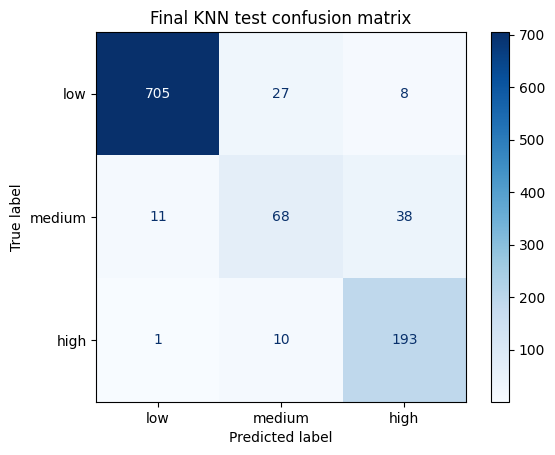

In [35]:
test_class_prediction = chosen_classifier.predict(X_test)
test_class_probability = chosen_classifier.predict_proba(X_test)
print("Test classification accuracy:", accuracy_score(y_test, test_class_prediction))
print("Test classification macro-F1:", f1_score(y_test, test_class_prediction, labels=CLASS_NAMES, average="macro", zero_division=0))
print(classification_report(y_test, test_class_prediction, labels=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_class_prediction, labels=CLASS_NAMES, cmap="Blues")
plt.title("Final KNN test confusion matrix")
plt.show()

Test regression MAE: 69.24895651003096
Test regression RMSE: 129.87847149361565
Test regression R2: 0.9102923620988556


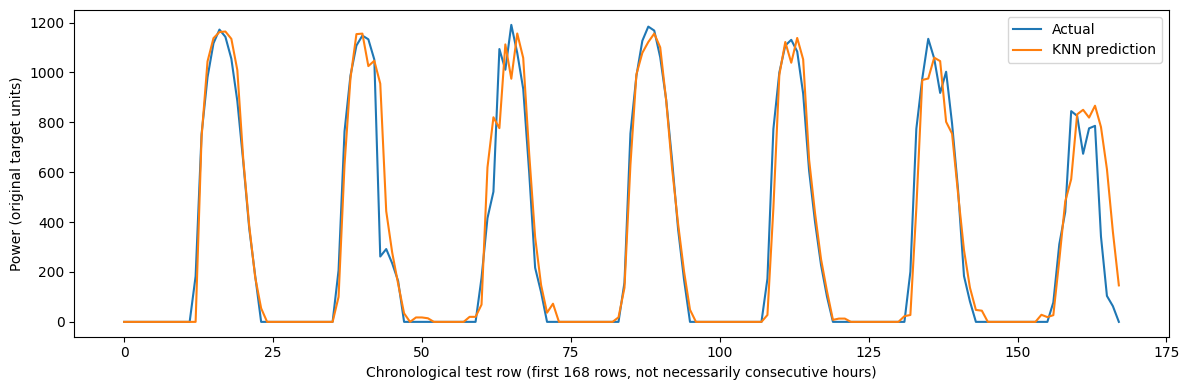

In [36]:
test_power_prediction = chosen_regressor.predict(X_test)
print("Test regression MAE:", mean_absolute_error(y_test_power, test_power_prediction))
print("Test regression RMSE:", np.sqrt(mean_squared_error(y_test_power, test_power_prediction)))
print("Test regression R2:", r2_score(y_test_power, test_power_prediction))
plt.figure(figsize=(12, 4))
plt.plot(y_test_power.to_numpy()[:168], label="Actual")
plt.plot(test_power_prediction[:168], label="KNN prediction")
plt.xlabel("Chronological test row (first 168 rows, not necessarily consecutive hours)")
plt.ylabel("Power (original target units)")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Save and reload both pipelines
Save preprocessing with each KNN estimator, input columns, label provenance and selection reasons. The exact physical class boundaries remain documented in Unit 3; no boundaries are learned here. KNN artifacts retain training representations and targets, so they can be larger than linear-model artifacts and require appropriate data-access controls.

Only load trusted joblib artifacts. Save outputs separately without overwriting source CSVs. In Colab, copy these files to persistent storage before runtime shutdown.

In [37]:
os.makedirs(CONFIG["output_dir"], exist_ok=True)
artifact = {
    "classifier": chosen_classifier,
    "regressor": chosen_regressor,
    "features": FEATURES,
    "class_names": CLASS_NAMES,
    "classification_target": TARGET,
    "regression_target": "target_power_t_plus_1",
    "label_source": "Prepared Unit 3 labels; boundaries learned from positive training targets",
    "selection_reasons": {
        "classification_k": k_reason, "classifier": classifier_reason,
        "regression_k": regression_k_reason, "regressor": regressor_reason,
    },
    "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
artifact_path = os.path.join(CONFIG["output_dir"], "knn_artifact.joblib")
joblib.dump(artifact, artifact_path)
test_output = test_data[["day", "hour", TARGET, "target_power_t_plus_1"]].copy()
test_output["predicted_class"] = test_class_prediction
test_output["predicted_power"] = test_power_prediction
test_output.to_csv(os.path.join(CONFIG["output_dir"], "test_predictions.csv"), index=False)
print("Saved outputs:", CONFIG["output_dir"])

Saved outputs: /content/outputs/04_05_k_nearest_neighbors


In [38]:
loaded_artifact = joblib.load(artifact_path)
new_measurements = X_test.head(5)[loaded_artifact["features"]]
reloaded_classes = loaded_artifact["classifier"].predict(new_measurements)
reloaded_power = loaded_artifact["regressor"].predict(new_measurements)
np.testing.assert_array_equal(reloaded_classes, test_class_prediction[:5])
np.testing.assert_allclose(reloaded_power, test_power_prediction[:5])
np.testing.assert_allclose(loaded_artifact["classifier"].predict_proba(new_measurements), test_class_probability[:5])
print("Reload checks passed.")

Reload checks passed.


## 12. Limitations and recap
- KNN stores examples: fitting is simple, but prediction and storage can be expensive.
- Distances depend on scaling, encoding and feature relevance. High dimensionality can make neighborhoods less informative.
- Correlated channels, noise, class imbalance and temporal distribution changes can distort neighbors or votes.
- Small-K training scores are optimistic because a training query can select itself.
- KNN has no coefficients, epochs or learning rate. K, weights and distance metric are its central settings here.
- Regression averages observed neighbor targets; it cannot extrapolate beyond their range.
- Validation selects settings. Test reports the performance of already fixed choices.

**Discuss:** Which K performed best for each task? Did distance weighting help? Did Manhattan distance change classification quality? Are the inspected neighbors physically plausible? Why might a new season or operating regime cause poor predictions?

**Optional later experiment:** compare alternative feature subsets or category weights using validation only. Do not repeatedly tune on the final test.

**Execution note:** structure, Python syntax and the complete workflow are checked on synthetic data during preparation. No run or performance on the original PV CSVs is claimed.